# Week 1: First ML Model with scikit-learn
## Wisconsin Breast Cancer Classification

**Internship:** SkillAudit.ai  
**Task:** Train and compare Logistic Regression and Random Forest classifiers.

### Objectives
- Load and explore the Wisconsin Breast Cancer dataset.
- Prepare a reproducible, stratified train/test split.
- Train Logistic Regression with feature standardization and a Random Forest classifier.
- Compare accuracy, precision, recall, and F1-score.
- Visualize model performance with accuracy and confusion-matrix plots.
- Inspect Random Forest feature importances.

## 1. Import libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 2. Load the dataset

The built-in Wisconsin Breast Cancer dataset contains 569 observations and 30 numeric features. The target has two classes: malignant and benign.

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
# scikit-learn encodes malignant as 0 and benign as 1.
y = pd.Series(data.target, name="target")
target_names = data.target_names

print(f"Dataset shape: {X.shape}")
print(f"Target classes: {list(target_names)}")
print(f"Target encoding: 0 = {target_names[0]}, 1 = {target_names[1]}")


Dataset shape: (569, 30)
Target classes: [np.str_('malignant'), np.str_('benign')]
Target encoding: 0 = malignant, 1 = benign


## 3. Basic exploratory data analysis

Inspect the first rows, data types, summary statistics, and missing values.

In [3]:
display(X.head())
display(X.describe().T.head(10))

print("\\nData types:")
print(X.dtypes.value_counts())

print("\\nMissing values in features:", int(X.isnull().sum().sum()))
print("Missing values in target:", int(y.isnull().sum()))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


\nData types:
float64    30
Name: count, dtype: int64
\nMissing values in features: 0
Missing values in target: 0


## 4. Visualize class distribution

This chart shows how many observations belong to each target class.

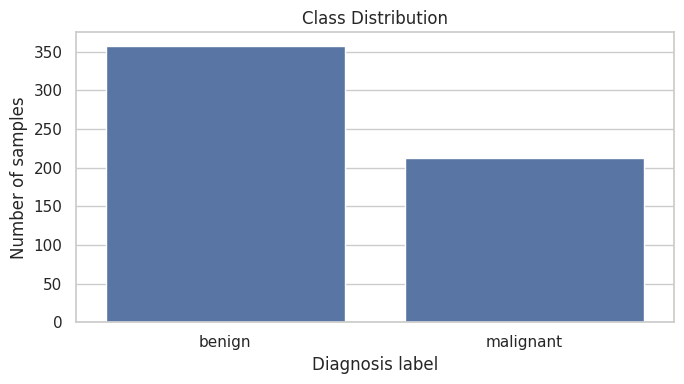

,count
target,
benign,357
malignant,212


In [4]:
class_counts = y.map({0: "malignant", 1: "benign"}).value_counts()

plt.figure(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("Class Distribution")
plt.xlabel("Diagnosis label")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

display(class_counts.rename("count").to_frame())


## 5. Stratified 80/20 train/test split

Stratification preserves approximately the same class proportions in both subsets. The fixed random state makes the split reproducible.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("\\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())
print("\\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index())


Training samples: 455
Testing samples: 114
\nTraining class proportions:
target
0    0.373626
1    0.626374
Name: proportion, dtype: float64
\nTesting class proportions:
target
0    0.368421
1    0.631579
Name: proportion, dtype: float64


## 6. Train Logistic Regression

Logistic Regression is placed in a pipeline with `StandardScaler`. Scaling is fitted only on the training data by the pipeline, which helps prevent data leakage.

In [6]:
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

logistic_pipeline.fit(X_train, y_train)
y_pred_logistic = logistic_pipeline.predict(X_test)

print("Logistic Regression training complete.")


Logistic Regression training complete.


## 7. Train Random Forest

Random Forest combines predictions from multiple decision trees. Tree-based models generally do not require feature scaling.

In [7]:
random_forest = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)
y_pred_rf = random_forest.predict(X_test)

print("Random Forest training complete.")


Random Forest training complete.


## 8. Evaluate and compare both models

Precision, recall, and F1-score are calculated using the **malignant** class (label `0`) as the positive class. This makes the meaning of recall explicit: among malignant samples in this test split, how many were identified as malignant. Accuracy is the fraction of all test predictions that are correct.

In [8]:
def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (malignant)": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Recall (malignant)": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1-score (malignant)": f1_score(y_true, y_pred, pos_label=0, zero_division=0)
    }

results = pd.DataFrame([
    calculate_metrics(y_test, y_pred_logistic, "Logistic Regression"),
    calculate_metrics(y_test, y_pred_rf, "Random Forest")
]).set_index("Model")

display(results.round(4))


,Accuracy,Precision (malignant),Recall (malignant),F1-score (malignant)
Model,,,,
Logistic Regression,0.9825,0.9762,0.9762,0.9762
Random Forest,0.9474,0.9286,0.9286,0.9286


## 9. Accuracy comparison chart

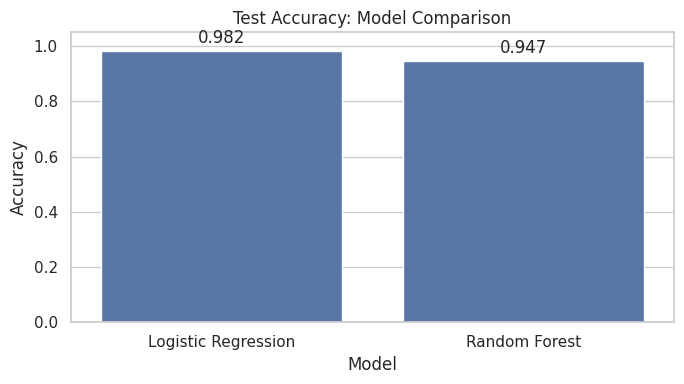

In [9]:
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    x=results.index,
    y=results["Accuracy"].values
)
ax.set_ylim(0, 1.05)
ax.set_title("Test Accuracy: Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()


## 10. Confusion matrices

Rows represent the true class and columns represent the predicted class. Class labels are shown as malignant and benign.

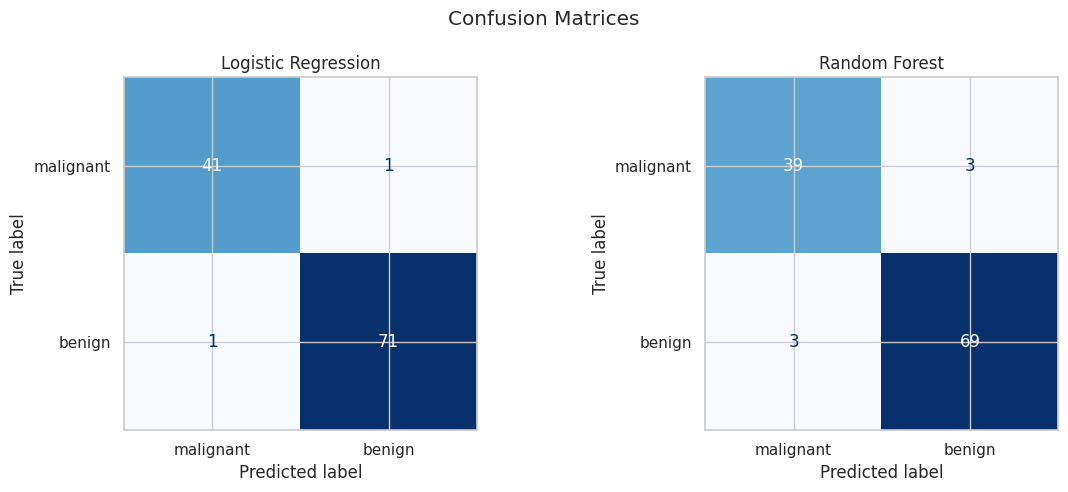

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in [
    (axes[0], y_pred_logistic, "Logistic Regression"),
    (axes[1], y_pred_rf, "Random Forest")
]:
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["malignant", "benign"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)

plt.suptitle("Confusion Matrices")
plt.tight_layout()
plt.show()


## 11. Classification reports

The reports include precision, recall, F1-score, and support for both classes. Review the malignant-class recall carefully rather than relying on accuracy alone.

In [11]:
print("LOGISTIC REGRESSION")
print(classification_report(
    y_test, y_pred_logistic,
    labels=[0, 1],
    target_names=["malignant", "benign"],
    zero_division=0
))

print("\\nRANDOM FOREST")
print(classification_report(
    y_test, y_pred_rf,
    labels=[0, 1],
    target_names=["malignant", "benign"],
    zero_division=0
))


LOGISTIC REGRESSION
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

\nRANDOM FOREST
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



## 12. Random Forest feature importance

Feature importance indicates how much each feature contributed to reducing impurity across the fitted trees. It describes model behavior, not cause-and-effect or clinical importance.

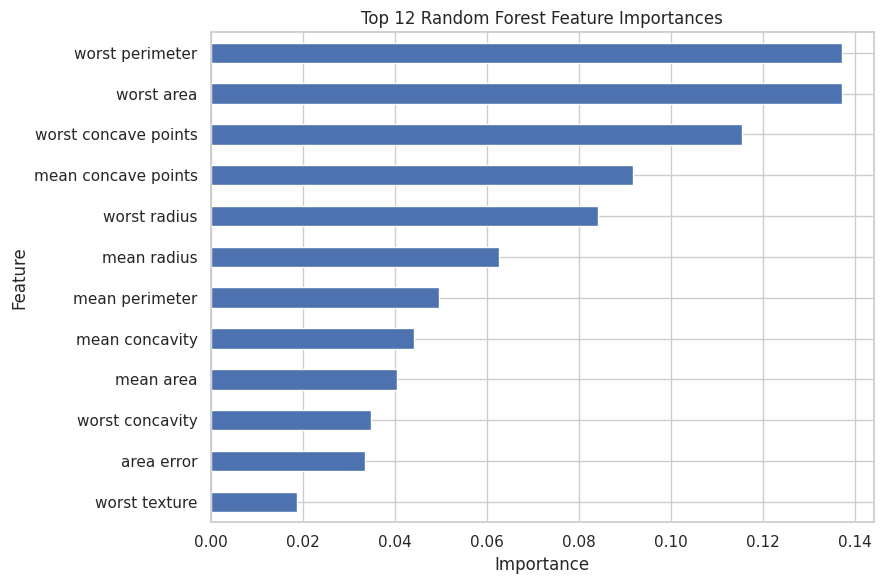

,importance
worst perimeter,0.137344
worst area,0.137312
worst concave points,0.115502
mean concave points,0.091774
worst radius,0.084111
mean radius,0.062741
mean perimeter,0.049680
mean concavity,0.044142
mean area,0.040508
worst concavity,0.034837


In [12]:
importances = pd.Series(
    random_forest.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

top_features = importances.head(12).sort_values()

plt.figure(figsize=(9, 6))
top_features.plot(kind="barh")
plt.title("Top 12 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(importances.head(12).rename("importance").to_frame())


## 13. Results and conclusion

Use the metric table and plots above to describe the observed performance on this particular held-out test split.

- Compare the two models using accuracy, precision, recall, and F1-score.
- Note which model has higher malignant-class recall.
- Refer to the confusion matrices to describe false negatives and false positives.
- Feature importance provides a view into the Random Forest model, but does not establish medical significance.

### Limitations
1. This is a single train/test split; scores can vary with a different split.
2. The dataset is a small, curated public dataset and may not represent real-world populations or clinical settings.
3. Metrics depend on the chosen threshold and class definition.
4. No external validation, calibration, clinical review, or prospective testing is performed.
5. The models are for learning only and are **not suitable for diagnosis, screening, treatment, or other medical decisions**.

### Final takeaway
This exercise demonstrates a reproducible scikit-learn workflow for binary classification and model comparison. The better model for this split should be identified from the measured metrics, not assumed in advance.


## 14. Reproducibility check



In [13]:
print("Experiment configuration")
print("------------------------")
print("Dataset: Wisconsin Breast Cancer (scikit-learn)")
print("Train/test split: 80/20, stratified")
print("Random state:", RANDOM_STATE)
print("Models: Logistic Regression (StandardScaler pipeline), Random Forest")
print("\\nMetric summary:")
display(results.round(4))
print("\\nNotebook run completed.")


Experiment configuration
------------------------
Dataset: Wisconsin Breast Cancer (scikit-learn)
Train/test split: 80/20, stratified
Random state: 42
Models: Logistic Regression (StandardScaler pipeline), Random Forest
\nMetric summary:


,Accuracy,Precision (malignant),Recall (malignant),F1-score (malignant)
Model,,,,
Logistic Regression,0.9825,0.9762,0.9762,0.9762
Random Forest,0.9474,0.9286,0.9286,0.9286


\nNotebook run completed.
